# Milestone 4 | Model Validation

## Objective

This notebook evaluates the reliability and
limitations of the statistical models developed
in the previous notebooks.

The analysis focuses on:

1. Missing data and potential selection bias
2. Data distributions and model assumptions
3. Sensitivity to extreme arrival delays
4. Out-of-sample model performance
5. Final findings and limitations

The goal is to determine whether the statistical
findings remain consistent under different
analytical conditions.

In [4]:
#%pip install scikit-learn

In [5]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load cleaned dataset
flights = pd.read_csv("data/cleaned/analysis_ready_flights.csv")

print("Dataset shape:", flights.shape)
print("Total flights:", len(flights))

Dataset shape: (327346, 34)
Total flights: 327346


## 1. Missing Data and Potential Selection Bias

Model 2 uses complete-case analysis because some
weather variables contain missing values.

To evaluate whether excluding these observations
may affect the results, we compare flights included
in and excluded from the regression sample based on
arrival delay, season, airline, and airport.

In [6]:
# Define variables used in Model 2
model2_cols = [
    "arr_delay", "season", "carrier",
    "scheduled_hour", "distance", "origin",
    "temp", "humid", "wind_speed",
    "precip", "pressure", "visib"
]

# Identify complete and incomplete observations
complete_mask = flights[model2_cols].notna().all(axis=1)

included = flights.loc[complete_mask].copy()
excluded = flights.loc[~complete_mask].copy()

# Check sample sizes
sample_summary = pd.DataFrame({
    "Sample": ["Full Dataset", "Included", "Excluded"],
    "Flight Count": [
        len(flights),
        len(included),
        len(excluded)
    ]
})

sample_summary["Percentage"] = (
    sample_summary["Flight Count"] / len(flights) * 100
).round(2)

display(sample_summary)

# Validate sample sizes
assert len(included) + len(excluded) == len(flights)
assert included[model2_cols].isna().sum().sum() == 0

print("Sample validation passed.")

,Sample,Flight Count,Percentage
0,Full Dataset,327346,100.00
1,Included,291140,88.94
2,Excluded,36206,11.06


Sample validation passed.


In [7]:
# Compare arrival delay statistics
delay_comparison = pd.DataFrame({
    "Included": included["arr_delay"].describe(),
    "Excluded": excluded["arr_delay"].describe()
}).T

delay_comparison["Late Arrival Rate (%)"] = [
    (included["arr_delay"] > 15).mean() * 100,
    (excluded["arr_delay"] > 15).mean() * 100
]

display(delay_comparison.round(2))

# Calculate difference in mean arrival delay
mean_difference = (
    excluded["arr_delay"].mean()
    - included["arr_delay"].mean()
)

print(f"Mean difference (Excluded - Included): "
      f"{mean_difference:.2f} minutes")

,count,mean,std,min,25%,50%,75%,max,Late Arrival Rate (%)
Included,291140.0,4.76,41.95,-86.0,-17.0,-6.0,12.0,1272.0,21.82
Excluded,36206.0,24.07,59.39,-79.0,-11.0,5.0,38.0,931.0,38.99


Mean difference (Excluded - Included): 19.31 minutes


In [8]:
# Welch's two-sample t-test
t_stat, p_value = stats.ttest_ind(
    excluded["arr_delay"],
    included["arr_delay"],
    equal_var=False
)

print(f"Welch's t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4e}")
print(f"Mean difference: {mean_difference:.2f} minutes")

# Standardized mean difference
pooled_sd = np.sqrt(
    (included["arr_delay"].var()
     + excluded["arr_delay"].var()) / 2
)

smd = mean_difference / pooled_sd

print(f"Standardized mean difference: {smd:.4f}")

Welch's t-statistic: 60.0348
p-value: 0.0000e+00
Mean difference: 19.31 minutes
Standardized mean difference: 0.3756


In [9]:
# Compare the composition of included and excluded flights
for variable in ["season", "carrier", "origin"]:

    composition = pd.DataFrame({
        "Included (%)":
            included[variable].value_counts(normalize=True) * 100,
        "Excluded (%)":
            excluded[variable].value_counts(normalize=True) * 100
    }).fillna(0)

    composition["Difference (pp)"] = (
        composition["Excluded (%)"]
        - composition["Included (%)"]
    )

    print(f"\nSample composition by {variable}")
    display(composition.round(2))


Sample composition by season


,Included (%),Excluded (%),Difference (pp)
season,,,
Fall,26.05,18.63,-7.43
Spring,25.63,24.78,-0.85
Summer,25.61,26.38,0.76
Winter,22.70,30.22,7.52



Sample composition by carrier


,Included (%),Excluded (%),Difference (pp)
carrier,,,
9E,5.36,4.67,-0.69
AA,9.76,9.74,-0.02
AS,0.22,0.23,0.01
B6,16.55,16.22,-0.32
DL,14.55,14.66,0.11
EV,15.66,15.25,-0.41
F9,0.20,0.24,0.04
FL,0.97,0.95,-0.02
HA,0.10,0.13,0.03



Sample composition by origin


,Included (%),Excluded (%),Difference (pp)
origin,,,
EWR,35.54,37.75,2.21
JFK,33.57,31.34,-2.23
LGA,30.90,30.91,0.02


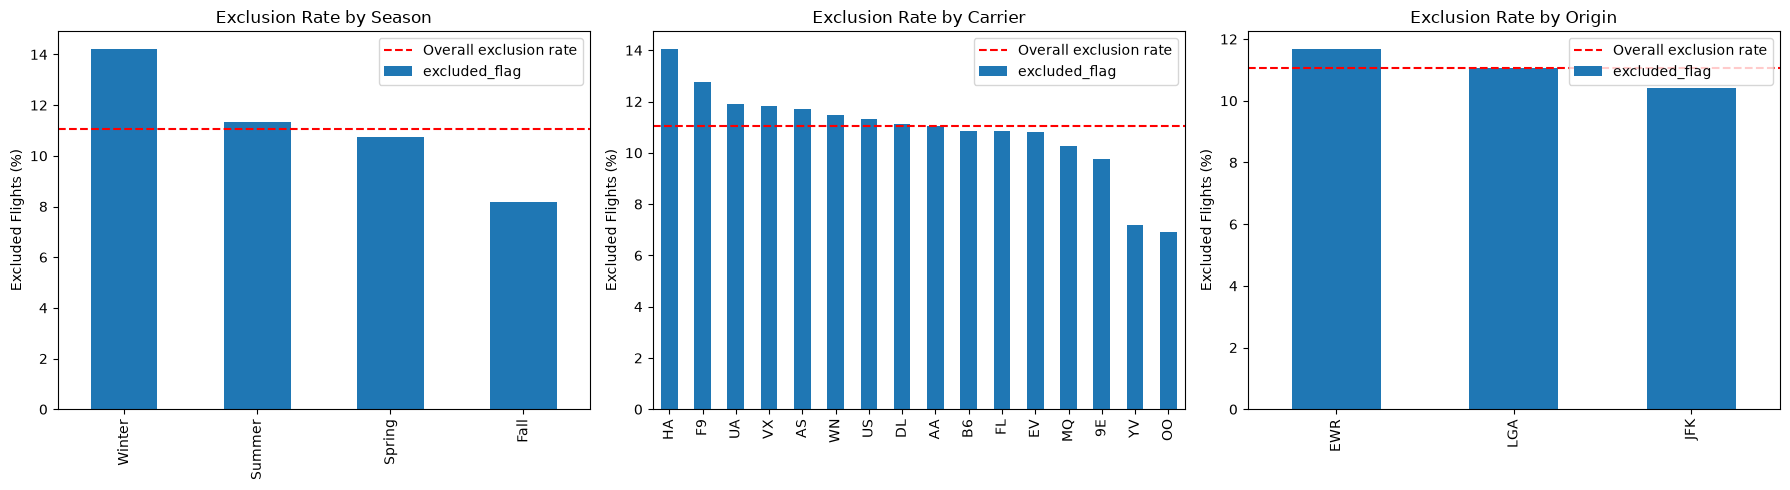

In [10]:
# Identify excluded flights
flights["excluded_flag"] = ~complete_mask

# Calculate exclusion rates by category
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, variable in zip(
    axes, ["season", "carrier", "origin"]
):

    exclusion_rate = (
        flights.groupby(variable)["excluded_flag"]
        .mean() * 100
    ).sort_values(ascending=False)

    exclusion_rate.plot(kind="bar", ax=ax)

    ax.axhline(
        flights["excluded_flag"].mean() * 100,
        color="red",
        linestyle="--",
        label="Overall exclusion rate"
    )

    ax.set_title(f"Exclusion Rate by {variable.title()}")
    ax.set_ylabel("Excluded Flights (%)")
    ax.set_xlabel("")
    ax.legend()

plt.tight_layout()
plt.show()

### Interpretation of Missing Data Analysis

Of the 327,346 flights, 36,206 flights (11.06%)
were excluded from the complete-case sample.

The excluded flights had a higher average arrival
delay than the included flights (24.07 vs. 4.76
minutes). Their median delay was also higher
(5 vs. -6 minutes).

The late arrival rate was 38.99% for excluded
flights compared with 21.82% for included flights.

Welch's t-test indicated a statistically significant
difference in mean arrival delays (p < 0.001).
The standardized mean difference was 0.3756,
suggesting that the difference is not negligible.

The sample composition also differed by season.
Winter flights accounted for a larger proportion
of the excluded sample, while Fall flights
accounted for a smaller proportion.

These findings suggest that the complete-case
sample may not fully represent the original
dataset. Excluding incomplete observations may
underrepresent flights with longer delays.

We retain complete-case analysis to ensure a fair
comparison between Model 1 and Model 2. However,
the potential selection bias should be considered
when interpreting and generalizing the results.

## 2. Data Distributions and Model Assumptions

Arrival delay is not normally distributed and
contains a long right tail.

We compare the distributions of the full dataset
and the complete-case sample to examine how
missing data treatment changes the distribution
of arrival delays.

In [11]:
# Compare distribution characteristics
distribution_summary = pd.DataFrame({
    "Full Sample": flights["arr_delay"],
    "Complete-case Sample": included["arr_delay"],
    "Excluded Sample": excluded["arr_delay"]
}).agg([
    "mean",
    "median",
    "std",
    "skew",
    "kurt",
    "min",
    "max"
]).T

display(distribution_summary.round(4))

,mean,median,std,skew,kurt,min,max
Full Sample,6.8954,-5.0,44.6333,3.7168,29.2330,-86.0,1272.0
Complete-case Sample,4.7596,-6.0,41.9530,3.8582,32.7497,-86.0,1272.0
Excluded Sample,24.0694,5.0,59.3867,2.8703,16.1043,-79.0,931.0


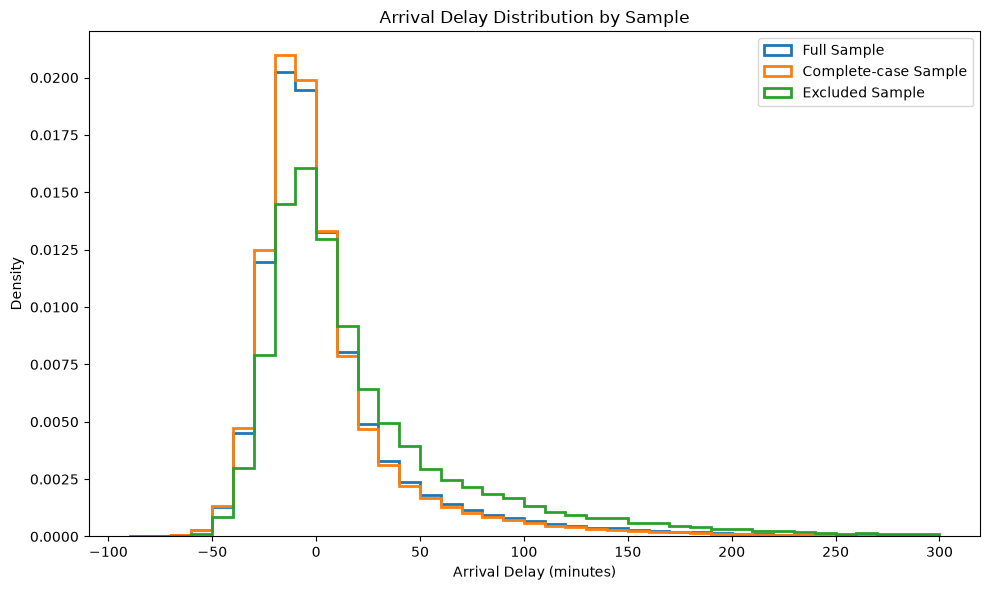

In [12]:
# Compare arrival delay distributions
fig, ax = plt.subplots(figsize=(10, 6))

bins = np.arange(-90, 301, 10)

for label, data in [
    ("Full Sample", flights),
    ("Complete-case Sample", included),
    ("Excluded Sample", excluded)
]:
    ax.hist(
        data["arr_delay"],
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        label=label
    )

ax.set_title("Arrival Delay Distribution by Sample")
ax.set_xlabel("Arrival Delay (minutes)")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.show()

## 3. Outlier Sensitivity Analysis

Extreme arrival delays may influence regression
coefficients and model performance.

Since these observations may represent actual
flight delays, we retain them in the main analysis.

To evaluate their influence, we compare regression
results before and after excluding observations
outside the 1.5 × IQR boundaries.

This sensitivity analysis helps determine whether
the main findings depend heavily on extreme values.

In [13]:
# Calculate IQR boundaries
Q1 = included["arr_delay"].quantile(0.25)
Q3 = included["arr_delay"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outlier_mask = (
    (included["arr_delay"] < lower_bound) |
    (included["arr_delay"] > upper_bound)
)

outliers = included.loc[outlier_mask].copy()
filtered = included.loc[~outlier_mask].copy()

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower boundary: {lower_bound:.2f}")
print(f"Upper boundary: {upper_bound:.2f}")

print(f"\nOriginal sample: {len(included):,}")
print(f"Outliers: {len(outliers):,}")
print(f"Filtered sample: {len(filtered):,}")
print(f"Outlier percentage: {outlier_mask.mean()*100:.2f}%")

assert len(filtered) + len(outliers) == len(included)

Q1: -17.00
Q3: 12.00
IQR: 29.00
Lower boundary: -60.50
Upper boundary: 55.50

Original sample: 291,140
Outliers: 23,997
Filtered sample: 267,143
Outlier percentage: 8.24%


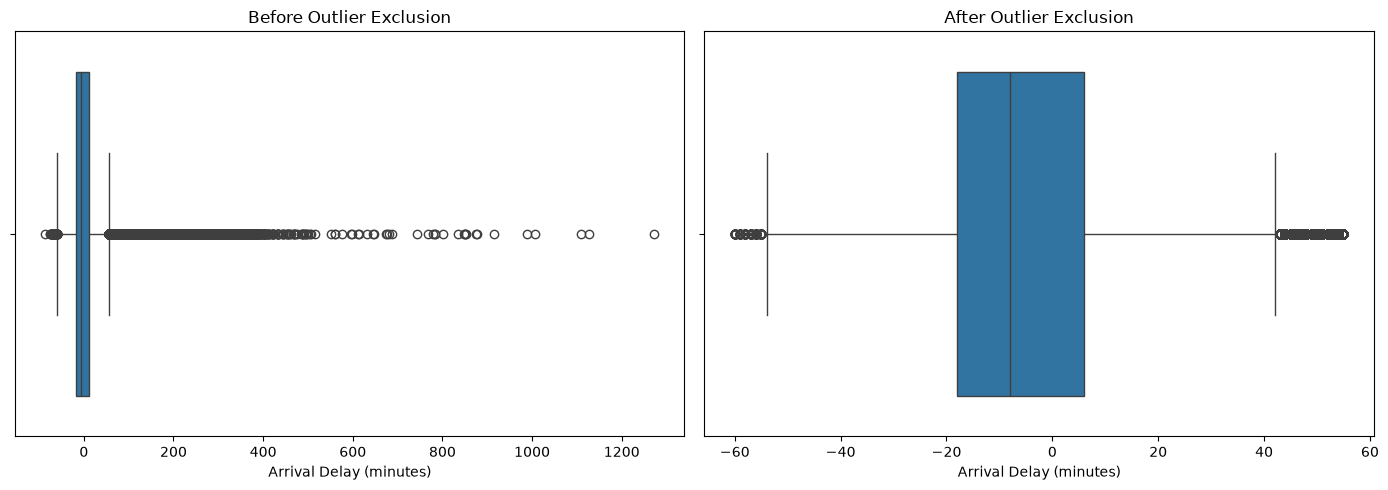

In [14]:
# Compare arrival delay distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    x=included["arr_delay"],
    ax=axes[0]
)
axes[0].set_title("Before Outlier Exclusion")
axes[0].set_xlabel("Arrival Delay (minutes)")

sns.boxplot(
    x=filtered["arr_delay"],
    ax=axes[1]
)
axes[1].set_title("After Outlier Exclusion")
axes[1].set_xlabel("Arrival Delay (minutes)")

plt.tight_layout()
plt.show()

### Regression Sensitivity Check

We estimate Model 2 using the original complete-case
sample and the sample without IQR-flagged observations.

Both models use the same predictors and reference
categories to maintain a consistent model specification.

HC3 robust standard errors are used for statistical
inference.

In [15]:
# Define predictors
flight_predictors = [
    "season", "carrier", "scheduled_hour",
    "distance", "origin"
]

weather_predictors = [
    "temp", "humid", "wind_speed",
    "precip", "pressure", "visib"
]

# Define consistent reference categories
reference_categories = {
    "season": ["Winter", "Spring", "Summer", "Fall"],
    "carrier": [
        "AA", "AS", "B6", "DL", "EV", "F9",
        "FL", "HA", "MQ", "OO", "UA", "US",
        "VX", "WN", "YV", "9E"
    ],
    "origin": ["JFK", "LGA", "EWR"]
}

# Prepare regression variables
def prepare_regression_data(data, include_weather=True):

    predictors = flight_predictors.copy()

    if include_weather:
        predictors += weather_predictors

    X = data[predictors].copy()
    y = data["arr_delay"].copy()

    for column, categories in reference_categories.items():
        X[column] = pd.Categorical(
            X[column],
            categories=categories
        )

    X = pd.get_dummies(
        X,
        columns=["season", "carrier", "origin"],
        drop_first=True,
        dtype=int
    )

    X = sm.add_constant(X, has_constant="add")

    return X.astype(float), y.astype(float)

In [16]:
# Model 2 with all complete-case observations
X_original, y_original = prepare_regression_data(included)

model_original = sm.OLS(
    y_original, X_original
).fit(cov_type="HC3")

# Model 2 without IQR-flagged observations
X_filtered, y_filtered = prepare_regression_data(filtered)

model_filtered = sm.OLS(
    y_filtered, X_filtered
).fit(cov_type="HC3")

print("Original Model R-squared:",
      round(model_original.rsquared, 4))

print("Filtered Model R-squared:",
      round(model_filtered.rsquared, 4))

print("Both models fitted successfully.")

Original Model R-squared: 0.0797
Filtered Model R-squared: 0.0611
Both models fitted successfully.


In [17]:
# Compare model statistics
sensitivity_summary = pd.DataFrame({
    "Original Model": {
        "Observations": model_original.nobs,
        "R-squared": model_original.rsquared,
        "Adjusted R-squared": model_original.rsquared_adj,
        "Mean Arrival Delay": y_original.mean(),
        "Residual SD": model_original.resid.std()
    },
    "Filtered Model": {
        "Observations": model_filtered.nobs,
        "R-squared": model_filtered.rsquared,
        "Adjusted R-squared": model_filtered.rsquared_adj,
        "Mean Arrival Delay": y_filtered.mean(),
        "Residual SD": model_filtered.resid.std()
    }
})

display(sensitivity_summary.round(4))

,Original Model,Filtered Model
Observations,291140.0000,267143.0000
R-squared,0.0797,0.0611
Adjusted R-squared,0.0796,0.0610
Mean Arrival Delay,4.7596,-4.8811
Residual SD,40.2474,19.2441


In [18]:
# Compare key regression coefficients
key_variables = [
    "scheduled_hour",
    "distance",
    "season_Spring",
    "season_Summer",
    "season_Fall",
    "temp",
    "humid",
    "wind_speed",
    "precip",
    "pressure",
    "visib"
]

coefficient_comparison = pd.DataFrame({
    "Original Coefficient":
        model_original.params[key_variables],

    "Filtered Coefficient":
        model_filtered.params[key_variables],

    "Original p-value":
        model_original.pvalues[key_variables],

    "Filtered p-value":
        model_filtered.pvalues[key_variables]
})

# Calculate coefficient changes
coefficient_comparison["Change (%)"] = (
    (
        coefficient_comparison["Filtered Coefficient"]
        - coefficient_comparison["Original Coefficient"]
    )
    / coefficient_comparison["Original Coefficient"].abs()
    * 100
)

# Check whether coefficient directions remain consistent
coefficient_comparison["Same Direction"] = (
    np.sign(coefficient_comparison["Original Coefficient"])
    == np.sign(coefficient_comparison["Filtered Coefficient"])
)

display(coefficient_comparison)

,Original Coefficient,Filtered Coefficient,Original p-value,Filtered p-value,Change (%),Same Direction
scheduled_hour,1.555445,0.511423,0.000000e+00,0.000000e+00,-67.120481,True
distance,-0.001044,-0.000855,3.005156e-16,9.056524e-37,18.109110,True
season_Spring,-0.322430,-1.523506,1.786128e-01,2.659766e-35,-372.507803,True
season_Summer,5.893079,2.276407,2.573156e-59,3.245219e-36,-61.371513,True
season_Fall,-5.848021,-2.558887,2.123913e-130,2.594013e-88,56.243542,True
temp,-0.060654,-0.106724,2.324341e-17,2.242837e-190,-75.954824,True
humid,0.229213,0.048444,0.000000e+00,4.436030e-73,-78.865023,True
wind_speed,0.388695,0.158030,5.777772e-133,2.942955e-91,-59.343430,True
precip,70.584274,31.262307,1.959997e-14,6.598039e-14,-55.709246,True
pressure,-0.415930,-0.182862,2.503559e-287,1.920336e-220,56.035260,True


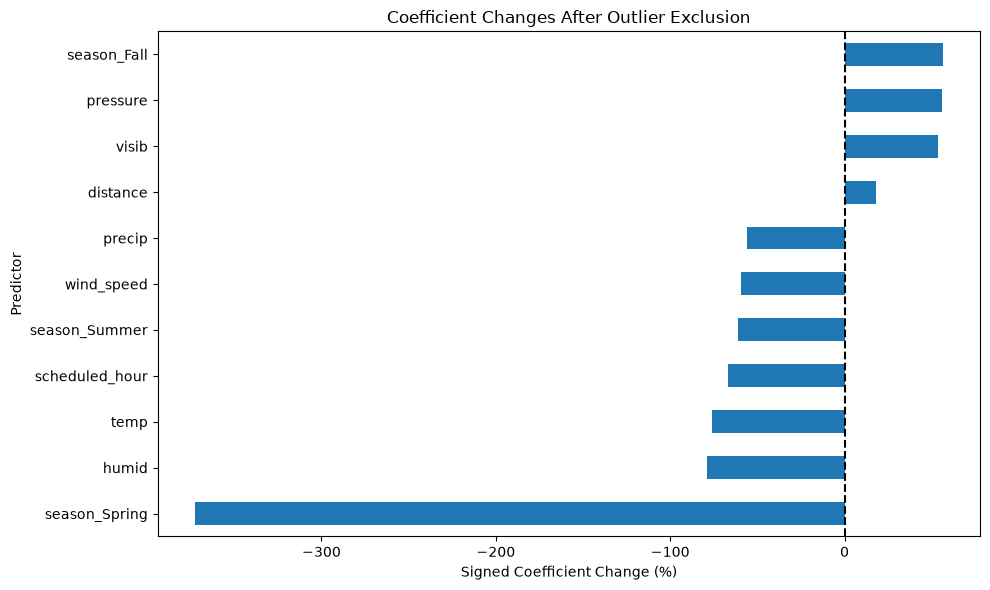

In [19]:
# Visualize changes in regression coefficients
plot_data = coefficient_comparison["Change (%)"].sort_values()

fig, ax = plt.subplots(figsize=(10, 6))

plot_data.plot(kind="barh", ax=ax)

ax.axvline(0, color="black", linestyle="--")

ax.set_title("Coefficient Changes After Outlier Exclusion")
ax.set_xlabel("Signed Coefficient Change (%)")
ax.set_ylabel("Predictor")

plt.tight_layout()
plt.show()